<div style="display:flex; align-items:center; gap:18px; text-align:left">

<div>
<p>Ingeniería en Información y Control de Gestión</p>
<p>Facultad de Economía y Negocios</p>
<p>Introducción a Machine Learning</p>
<p>Proyecto capstone: ejemplo resuelto de regresión</p>
</div>
</div>

# Ejemplo resuelto · regresión

Este notebook recorre los 16 pasos de la [plantilla del capstone](https://colab.research.google.com/github/sebastiancontz/ust-introduccion-machine-learning-colab/blob/main/ediciones/2026/notebooks/capstone-plantilla.ipynb) con `clientes_ventas.parquet`, el
archivo de las sesiones 6 y 9. Sirve para ver **cómo se ve cada paso resuelto**: qué código lleva, qué se
anota y qué sale para la presentación.

Es una guía, no un molde: su caso tiene otros datos, otra decisión y otros problemas, y sus decisiones
pueden ser distintas de las de acá. Lo que se copia es el **orden y el rigor**, no las cifras.

## Paso 0 · Librerías

In [1]:
%%capture
!pip install -q pandas numpy pyarrow matplotlib seaborn scikit-learn shap joblib

In [2]:
import os                          # revisa si los datos están en una carpeta local
import time                        # mide cuánto tarda cada modelo
import numpy as np                 # cálculo numérico
import pandas as pd                # tablas
import matplotlib.pyplot as plt    # gráficos
import seaborn as sns              # gráficos estadísticos
import shap                        # explicaciones del modelo
import joblib                      # guarda y carga el modelo
import sklearn                     # para anotar su versión

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.metrics import (roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, mean_absolute_error, silhouette_score)
from sklearn.cluster import KMeans

## Paso 1 · El canvas, antes de programar

- **Decisión que apoya el modelo y quién la toma:** el área comercial de una tienda en línea planifica,
  al inicio del trimestre, cuánto seguimiento dar a cada cliente según cuántas veces se espera que
  vuelva a comprar.
- **Qué es un registro:** un cliente.
- **Qué se predice y con qué horizonte; clasificación o regresión:** `facturas_futuras`, cuántas
  facturas tendrá el cliente en los **tres meses** siguientes al corte del 2011-09-01. Es regresión: el
  target es una cantidad.
- **Momento de la predicción:** el día del corte. Se conoce todo lo de los nueve meses anteriores (las
  columnas `_base`, la recencia y la antigüedad); no se sabe nada de lo que compra después.
- **Columnas que excluyen y por qué:** `id_cliente`, porque es un identificador.
- **Métrica y criterio de éxito:** el **promedio del error absoluto, en facturas por cliente**. El
  modelo tiene que equivocarse menos que el baseline, que predice para todos la mediana de entrenamiento.

In [3]:
SEMILLA = 42   # la misma en la muestra, la partición y cada modelo que sortea

ARCHIVO = 'clientes_ventas.parquet'
TARGET = 'facturas_futuras'
EXCLUIDAS = ['id_cliente']   # identificador: no describe al cliente

> **Para la presentación:** sección 1 del enunciado: el canvas completo y coherente.

## Paso 2 · Cargar los datos

In [4]:
REPO = 'https://raw.githubusercontent.com/sebastiancontz/ust-introduccion-machine-learning-colab/main/ediciones/2026/datasets/'
BASE = '../datasets/' if os.path.exists('../datasets') else REPO  # en Colab siempre se usa REPO

datos = pd.read_parquet(BASE + ARCHIVO)
print('registros y columnas:', datos.shape)
datos.head()

registros y columnas: (3314, 9)


,id_cliente,facturas_base,monto_base,productos_base,ticket_medio_base,recencia_dias,antiguedad_dias,mercado,facturas_futuras
0,12346,1,77183.60,1,77183.60,225,225,reino unido,0
1,12347,5,2790.86,82,558.17,29,267,exportacion,2
2,12348,3,1167.24,21,389.08,148,258,exportacion,1
3,12350,1,294.40,16,294.40,210,210,exportacion,0
4,12352,4,641.51,24,160.38,162,196,exportacion,3


## Paso 3 · La calidad de los datos

In [5]:
datos.info()   # tipos y valores no vacíos

<class 'pandas.DataFrame'>
RangeIndex: 3314 entries, 0 to 3313
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_cliente         3314 non-null   int64  
 1   facturas_base      3314 non-null   int64  
 2   monto_base         3314 non-null   float64
 3   productos_base     3314 non-null   int64  
 4   ticket_medio_base  3314 non-null   float64
 5   recencia_dias      3314 non-null   int64  
 6   antiguedad_dias    3314 non-null   int64  
 7   mercado            3314 non-null   str    
 8   facturas_futuras   3314 non-null   int64  
dtypes: float64(2), int64(6), str(1)
memory usage: 268.7 KB


In [6]:
print('vacíos en todo el archivo:', datos.isna().sum().sum())
print('filas idénticas a otra:', datos.duplicated().sum())

vacíos en todo el archivo: 0
filas idénticas a otra: 0


In [7]:
datos.describe().T.round(2)   # rangos de las numéricas

,count,mean,std,min,25%,50%,75%,max
id_cliente,3314.0,15283.70,1724.88,12346.0,13798.25,15242.50,16770.75,18287.00
facturas_base,3314.0,3.42,5.54,1.0,1.00,2.00,4.00,126.00
monto_base,3314.0,1553.22,5920.62,2.9,255.92,542.83,1340.10,175782.94
productos_base,3314.0,49.01,66.12,1.0,13.00,29.00,62.00,1188.00
ticket_medio_base,3314.0,397.76,1443.11,2.9,167.16,279.10,409.35,77183.60
recencia_dias,3314.0,92.29,76.74,0.0,27.00,72.50,146.00,273.00
antiguedad_dias,3314.0,175.74,77.84,0.0,117.00,184.00,257.00,273.00
facturas_futuras,3314.0,1.63,3.38,0.0,0.00,1.00,2.00,95.00


In [8]:
print(datos[TARGET].describe().round(2))
print('clientes que no vuelven (target = 0):', (datos[TARGET] == 0).sum())

count    3314.00
mean        1.63
std         3.38
min         0.00
25%         0.00
50%         1.00
75%         2.00
max        95.00
Name: facturas_futuras, dtype: float64
clientes que no vuelven (target = 0): 1367


**Problemas encontrados y cuántos registros afecta cada uno:**

- No hay vacíos ni filas repetidas.
- Las columnas de la ventana base tienen **colas largas**: unos pocos clientes compran mucho más que el
  resto (lo muestra la distancia entre el percentil 75 y el máximo). Son clientes reales, mayoristas
  probablemente: no se quitan.
- El target es un **conteo** con muchos ceros: el cliente que no vuelve vale 0, no es un faltante. Su
  promedio queda bastante por encima de su mediana, por la cola de clientes que compran mucho.

> **Para la presentación:** sección 2: registros, columnas y tipos; los problemas de calidad, con cifras.

## Paso 4 · Exploración: 2 o 3 gráficos relevantes

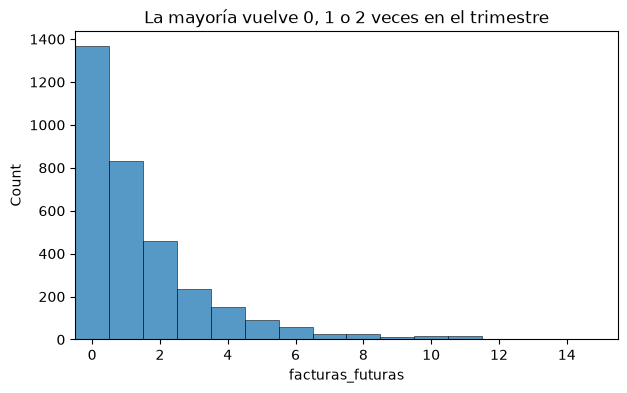

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=datos, x=TARGET, discrete=True, ax=ax)
ax.set_xlim(-0.5, 15.5)   # el eje se corta en 15: la cola llega mucho más lejos
ax.set_title('La mayoría vuelve 0, 1 o 2 veces en el trimestre')
plt.show()

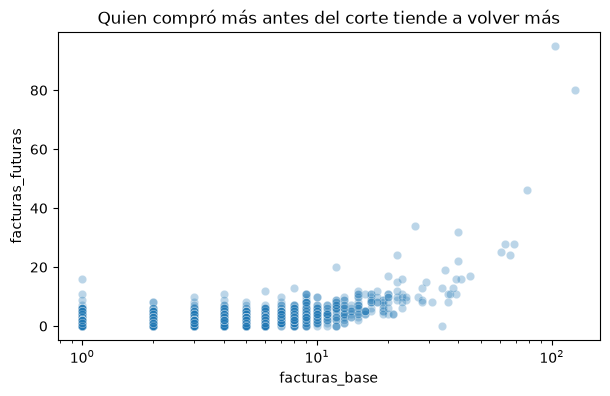

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=datos, x='facturas_base', y=TARGET, alpha=0.3, ax=ax)
ax.set_xscale('log')   # escala logarítmica: la cola de la ventana base aplasta al resto
ax.set_title('Quien compró más antes del corte tiende a volver más')
plt.show()

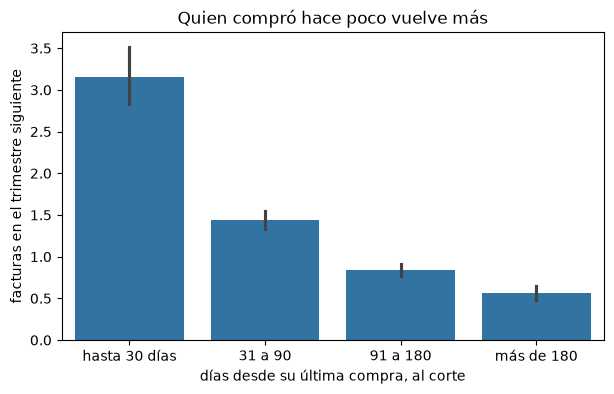

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
recencia_tramo = pd.cut(datos['recencia_dias'], bins=[-1, 30, 90, 180, 400],
                        labels=['hasta 30 días', '31 a 90', '91 a 180', 'más de 180'])
sns.barplot(x=recencia_tramo, y=datos[TARGET], ax=ax)   # promedio de cada tramo, con su intervalo
ax.set_xlabel('días desde su última compra, al corte')
ax.set_ylabel('facturas en el trimestre siguiente')
ax.set_title('Quien compró hace poco vuelve más')
plt.show()

**Lectura de cada gráfico** (qué muestra y qué decisión informa):

1. El reparto del target: casi todo está entre 0 y 2, con una cola larga. **Informa** la métrica: el
   promedio del error absoluto no se deja arrastrar tanto por la cola como el error cuadrático, y el
   baseline que le corresponde es la mediana.
2. Las facturas antes del corte frente a las de después: la relación existe pero es ruidosa.
   **Informa** que el historial de compras es la señal principal.
3. El promedio de facturas futuras por tramo de recencia: baja a medida que pasa más tiempo desde la
   última compra. **Informa** que la recencia aporta algo que el volumen no dice, y que la relación no
   es una recta: conviene probar árboles.

> **Para la presentación:** sección 2: cada gráfico con lo que muestra y qué decisión informa.

## Paso 5 · Preparación sin fuga

No hay filas que quitar ni muestra que tomar. El archivo ya separa en el tiempo predictoras y target
(las columnas `_base` son anteriores al corte), así que no hay que excluir nada más que el
identificador.

In [12]:
y = datos[TARGET]
X = datos.drop(columns=[TARGET] + EXCLUIDAS)

COLUMNAS_NUM = list(X.select_dtypes(include='number').columns)
COLUMNAS_CAT = list(X.select_dtypes(exclude='number').columns)
print('numéricas:', COLUMNAS_NUM)
print('categóricas:', COLUMNAS_CAT)

numéricas: ['facturas_base', 'monto_base', 'productos_base', 'ticket_medio_base', 'recencia_dias', 'antiguedad_dias']
categóricas: ['mercado']


In [13]:
ruta_numerica = Pipeline([
    ('rellenar', SimpleImputer(strategy='median')),   # la mediana de entrenamiento rellena los vacíos
    ('escalar', StandardScaler()),                    # promedio 0 y desviación 1
])
preparar = ColumnTransformer([
    ('num', ruta_numerica, COLUMNAS_NUM),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), COLUMNAS_CAT),
], verbose_feature_names_out=False).set_output(transform='pandas')   # una tabla con nombres, para SHAP

**Decisiones de preparación y su motivo:**

- Se excluye `id_cliente`: no describe al cliente.
- Se dejan los clientes de la cola larga: son reales y la decisión también los incluye.
- No se transforman las colas con logaritmo, para mantener el ejemplo simple. Sería una mejora a probar
  para la regresión lineal; a los árboles no les cambia.
- `mercado` pasa por *one-hot*.

> **Para la presentación:** secciones 1 y 2: qué columnas excluyeron y por qué; las decisiones de
> preparación.

## Paso 6 · La partición: entrenamiento, validación y prueba

El tiempo ya está resuelto dentro del archivo: todas las predictoras son anteriores al corte y el
target es posterior. Cada registro es un cliente distinto, así que la partición es **al azar**,
60/20/20. Es regresión: **sin** `stratify`.

In [14]:
# primero se aparta la prueba (20 %); lo que queda son entrenamiento y validación todavía juntos
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA)

# ese bloque se parte: el 25 % del 80 % que quedó es el 20 % del archivo
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=SEMILLA)

print('entrenamiento:', len(X_train), '· validación:', len(X_val), '· prueba:', len(X_test))

entrenamiento: 1988 · validación: 663 · prueba: 663


**Cómo partimos y por qué:** al azar, 60/20/20, con semilla 42; el horizonte temporal ya lo fija el
corte del archivo.

> **Para la presentación:** sección 3: cómo partieron los datos y por qué respeta la estructura de su
> caso.

## Paso 7 · El baseline y los candidatos

El baseline predice para todos la mediana de entrenamiento: con el promedio del error absoluto, es el
mejor valor constante. Los tres candidatos son los de la sesión 13.

In [15]:
candidatos = {
    'Baseline': DummyRegressor(strategy='median'),
    'Regresión lineal': LinearRegression(),
    'Árbol de decisión': DecisionTreeRegressor(max_depth=5, random_state=SEMILLA),
    'Random forest': RandomForestRegressor(max_features=0.33, random_state=SEMILLA),
}

## Paso 8 · La comparación, en validación

`mae` es el promedio del error absoluto, en facturas por cliente: cuántas facturas se equivoca el modelo,
en promedio, con cada cliente.

In [16]:
filas = []
modelos = {}
for nombre, estimador in candidatos.items():
    inicio = time.time()
    modelo = Pipeline([('preparar', clone(preparar)), ('modelo', clone(estimador))])
    modelo.fit(X_train, y_train)   # el único ajuste, y solo con entrenamiento
    filas.append({'modelo': nombre,
                  'segundos': round(time.time() - inicio, 1),
                  'mae_train': mean_absolute_error(y_train, modelo.predict(X_train)),
                  'mae_val': mean_absolute_error(y_val, modelo.predict(X_val))})
    modelos[nombre] = modelo   # se guarda para no reentrenar al elegido

tabla = pd.DataFrame(filas).round(3)
tabla

,modelo,segundos,mae_train,mae_val
0,Baseline,0.0,1.474,1.391
1,Regresión lineal,0.0,1.150,1.109
2,Árbol de decisión,0.0,1.079,1.207
3,Random forest,0.2,0.444,1.103


**Lectura de la tabla:** los tres modelos se equivocan menos que el baseline. La regresión lineal y el
bosque quedan casi empatados en validación (1,109 y 1,103 facturas). El bosque se equivoca mucho menos
en entrenamiento (0,444) que en validación: memorizó a los clientes que vio.

> **Para la presentación:** sección 3: las métricas de todos los modelos en una misma tabla.

## Paso 9 · (opcional) ¿La diferencia es real o es suerte de la partición?

¿El empate entre la regresión lineal y el bosque se sostiene? Cinco pliegues de `X_trainval`. `scikit-learn` da el error con signo negativo (más alto es mejor);
se le cambia el signo para leerlo en facturas.

In [17]:
pliegues = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
for nombre in ['Regresión lineal', 'Random forest']:
    puntajes = -cross_val_score(modelos[nombre], X_trainval, y_trainval, cv=pliegues,
                                scoring='neg_mean_absolute_error')
    print(f'{nombre}: error medio {puntajes.mean():.3f} facturas · desviación {puntajes.std():.3f}')

Regresión lineal: error medio 1.142 facturas · desviación 0.028


Random forest: error medio 1.165 facturas · desviación 0.039


## Paso 10 · La elección, antes de abrir la prueba

In [18]:
elegido = modelos['Regresión lineal']

**Elegimos** la regresión lineal **porque** empata con el bosque: en la validación cruzada su error
medio (1,142 facturas) es incluso algo menor que el del bosque (1,165), con una diferencia menor que la
variación entre pliegues. Ante un empate gana lo simple: no memoriza, es más rápida y su explicación es
directa. En regresión no hay umbral que elegir.

> **Para la presentación:** sección 3: cuál eligieron y por qué.

## Paso 11 · El cierre con prueba, una sola vez

In [19]:
mae_test = mean_absolute_error(y_test, elegido.predict(X_test))   # la prueba se abre acá, y solo acá
mae_baseline = mean_absolute_error(y_test, modelos['Baseline'].predict(X_test))
print('promedio del error absoluto en prueba, en facturas por cliente')
print('  regresión lineal:', round(mae_test, 2), '· baseline:', round(mae_baseline, 2))
print('  reducción frente al baseline:', round(100 * (1 - mae_test / mae_baseline)), '%')

promedio del error absoluto en prueba, en facturas por cliente
  regresión lineal: 1.16 · baseline: 1.44
  reducción frente al baseline: 19 %


> **Para la presentación:** secciones 3 y 5: el resultado final, frente al baseline y al criterio de
> éxito.

## Paso 12 · Interpretación con SHAP

In [20]:
casos = X_test.sample(n=200, random_state=SEMILLA)                 # 200 clientes de prueba
casos_prep = elegido.named_steps['preparar'].transform(casos)      # ya preparados, con nombres
explicador = shap.LinearExplainer(elegido.named_steps['modelo'], casos_prep)   # modelo lineal
explicacion = explicador(casos_prep)                               # aportes en facturas

# para los gráficos: las numéricas en sus unidades, no estandarizadas (los aportes no cambian)
originales = casos_prep.copy()
originales[COLUMNAS_NUM] = casos[COLUMNAS_NUM]
explicacion.data = originales.to_numpy()

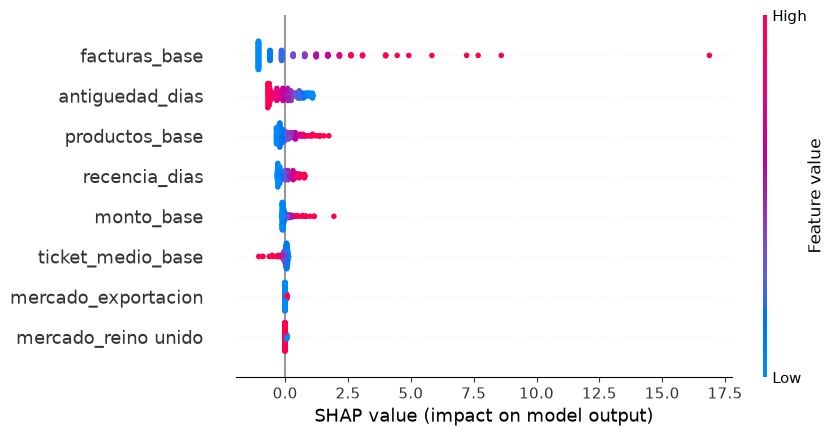

In [21]:
shap.plots.beeswarm(explicacion)   # global

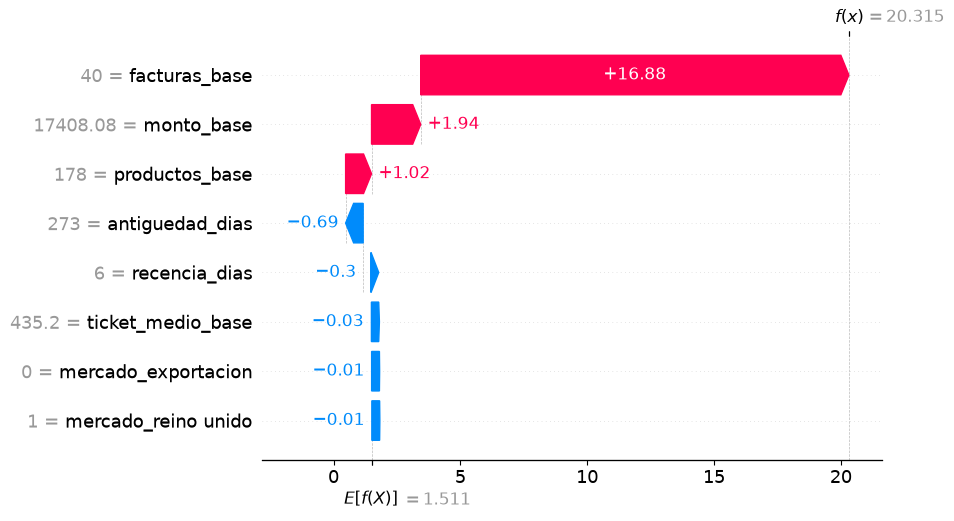

In [22]:
prediccion_casos = elegido.predict(casos)
mas_alto = int(np.argmax(prediccion_casos))   # el cliente con más facturas esperadas
shap.plots.waterfall(explicacion[mas_alto])

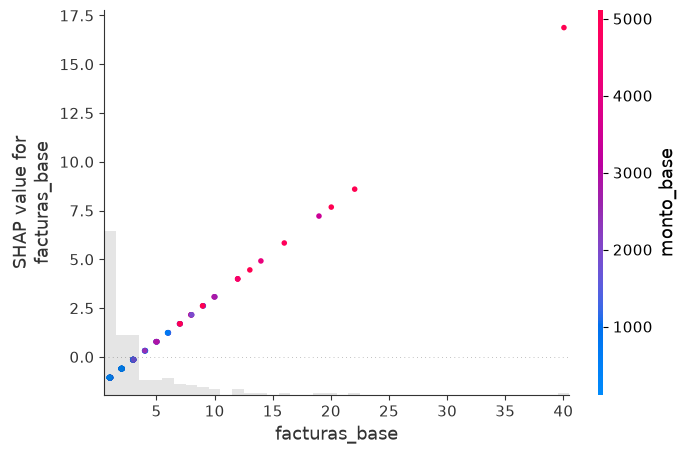

In [23]:
shap.plots.scatter(explicacion[:, 'facturas_base'], color=explicacion)   # dependencia: en un modelo lineal, una recta

**Qué permiten afirmar estas explicaciones y qué no:**

- Permiten afirmar que, **para este modelo**, las facturas antes del corte son lo que más mueve la
  predicción. En un modelo lineal el aporte es proporcional al valor, por eso la dependencia es una
  recta.
- En el gráfico global, una recencia alta **sube** la predicción, al revés del gráfico 3 del paso 4.
  No es una contradicción: el modelo lee la recencia junto con la antigüedad y las facturas, con las que
  está relacionada, y su aporte por separado no se interpreta solo.
- Permiten explicar al área comercial por qué un cliente concreto recibe una predicción alta.
- **No** permiten afirmar que contactar a un cliente para «bajar su recencia» lo haría comprar más:
  SHAP describe asociaciones que el modelo aprendió, no causas.

> **Para la presentación:** sección 4: la explicación global, la de un caso y la de dependencia,
> leídas como asociación.

## Paso 13 · De la cifra a la recomendación

| Pregunta | Respuesta del equipo |
|:--|:--|
| ¿Cuánto mejora el modelo frente al baseline, en la unidad de la decisión? | En prueba, el promedio del error absoluto baja de 1,44 a 1,16 facturas por cliente, un 19 % menos |
| ¿Se cumplió el criterio de éxito del canvas? ¿Qué cambió respecto de lo planificado y por qué? | Sí: se equivoca menos que el baseline. No cambió el plan |
| ¿Qué gana la organización al usar el modelo frente a no usarlo? | Ordena a los clientes por cuánto se espera que vuelvan, algo que el baseline no hace: le da a todos la misma cifra |
| ¿Qué riesgos y límites tiene? | Un solo corte (2011) y un trimestre que incluye la temporada navideña; los clientes de la cola pesan en el error; el modelo no sabe por qué un cliente deja de comprar |
| Si el modelo se usara, ¿qué habría que observar? | Al cerrar cada trimestre, el error real contra el predicho; si sube, reentrenar con un corte más reciente |

> **Para la presentación:** sección 5.

## Paso 14 · (opcional) Segmentación con K-means

Como en la sesión 9: las seis columnas de la ventana base, con `log1p` en las cuatro de cola larga
para que los mayoristas no acaparen la distancia, estandarizadas, y solo con entrenamiento.

In [24]:
VARIABLES_SEGMENTO = ['facturas_base', 'monto_base', 'productos_base', 'ticket_medio_base',
                      'recencia_dias', 'antiguedad_dias']
COLA_LARGA = ['facturas_base', 'monto_base', 'productos_base', 'ticket_medio_base']

segmentar = X_train[VARIABLES_SEGMENTO].copy()
segmentar[COLA_LARGA] = np.log1p(segmentar[COLA_LARGA])   # comprime la cola de los mayoristas
escalado = StandardScaler().fit_transform(segmentar)      # sin escalar, la de mayor rango domina

for k in range(2, 7):
    prueba_k = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(escalado)
    print(f'k = {k} · inercia {prueba_k.inertia_:.0f} · silhouette {silhouette_score(escalado, prueba_k.labels_):.3f}')

k = 2 · inercia 7695 · silhouette 0.316
k = 3 · inercia 6134 · silhouette 0.290


k = 4 · inercia 5285 · silhouette 0.244
k = 5 · inercia 4652 · silhouette 0.241


k = 6 · inercia 4237 · silhouette 0.240


In [25]:
K = 3
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(escalado)
perfil = X_train[VARIABLES_SEGMENTO].groupby(kmeans.labels_).median().round(1)   # en las unidades originales
perfil['clientes'] = pd.Series(kmeans.labels_).value_counts().sort_index().to_numpy()
perfil['facturas_futuras (mediana)'] = y_train.groupby(kmeans.labels_).median().to_numpy()
perfil

,facturas_base,monto_base,productos_base,ticket_medio_base,recencia_dias,antiguedad_dias,clientes,facturas_futuras (mediana)
0,1.0,274.8,16.0,201.1,181.0,210.0,602,0.0
1,1.0,339.1,19.0,232.5,56.5,89.0,636,0.0
2,4.0,1642.5,71.0,355.9,33.0,235.0,750,2.0


**Cuántos grupos:** el *silhouette* es más alto con 2 (0,316), pero con 3 baja poco (0,290) y separa a
los clientes nuevos de los dormidos, que piden acciones distintas. Elegimos 3 por utilidad.

**Nombre y acción de cada grupo** (medianas de la tabla):

- **Grupo 0, dormidos:** una compra, la última hace unos 6 meses. Casi no vuelven: una campaña de
  reactivación barata, o ninguna.
- **Grupo 1, nuevos:** una compra reciente y poca antigüedad. Tampoco vuelven todavía: el seguimiento
  apunta a la segunda compra.
- **Grupo 2, frecuentes:** cuatro facturas, compra reciente y antigüedad alta; son los que vuelven.
  Cuidarlos es la prioridad.

> **Para la presentación:** sección 6, optativa: grupos perfilados, nombrados y útiles para la decisión.

## Paso 15 · (opcional) Exportar el modelo y los resultados

In [26]:
joblib.dump(elegido, 'clientes_bosque.joblib')        # guarda el pipeline ajustado
cargado = joblib.load('clientes_bosque.joblib')       # lo recupera, sin reentrenar
print('mismas predicciones tras guardar y cargar:',
      np.array_equal(elegido.predict(X_val), cargado.predict(X_val)))

print('pandas', pd.__version__, '· numpy', np.__version__, '· scikit-learn', sklearn.__version__)
print('shap', shap.__version__, '· joblib', joblib.__version__)

mismas predicciones tras guardar y cargar: True
pandas 3.0.5 · numpy 2.4.6 · scikit-learn 1.9.0
shap 0.51.0 · joblib 1.5.3


## Antes de llevar cifras a la presentación

- [x] **Entorno de ejecución → Reiniciar sesión y ejecutar todo**: este notebook corre de arriba abajo.
- [x] Las cifras de este notebook son las de esa corrida.
- [x] La semilla (42) y las versiones de las librerías están anotadas; no se usó muestra.
- [x] La prueba se abrió una sola vez, después de elegir modelo.
- [x] Cada decisión tiene su motivo escrito en el paso que corresponde.

## Atribución de datos

- **Creador:** Chen, D. (2012)
- **Fuente:** [UCI Machine Learning Repository — *Online Retail II*, dataset 502](https://archive.ics.uci.edu/dataset/502/online+retail+ii)
- **Licencia:** [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)
- **Modificación:** obra derivada en tres pasos. Las columnas originales se renombraron al español en
  `snake_case`; se aplicaron las siete decisiones de limpieza de la clase 4; y se agregó por cliente con
  un corte temporal, quedando 3.314 registros y 9 columnas.